In [145]:
import numpy as np
import pandas as pd
import plotly.express as px
import matplotlib as mpl
import matplotlib.pyplot as plt
from sklearn import decomposition

# set up data
# food_waste = pd.read_csv("Food_Waste_Characterization_perc.csv")
food_waste = pd.read_csv("Food_waste_characterization.csv")
food_waste_groups = food_waste.groupby('Group')

macros = food_waste[['Fat.Perc','Protein.Perc','Carbohydrate.Perc']].copy().to_numpy()

# food_waste['fats'] = (food_waste['VS.Perc']*food_waste['Fat.Perc'])/100
# food_waste['proteins'] = (food_waste['VS.Perc']*food_waste['Protein.Perc'])/100
# food_waste['carbs'] = (food_waste['VS.Perc']*food_waste['Carbohydrate.Perc'])/100
# macros = food_waste[['fats','proteins','carbs']].copy().to_numpy()

In [ ]:
labels = {'0':'Fat %', '1':'Protein %', '2':'Carb %'}
# labels = {'0':'fat per 100g', '1':'protein per 100g', '2':'carbs per 100g'}
fig = px.scatter_3d(macros, x=0, y=1, z=2, labels=labels, color=food_waste['Group'])
fig.show()
# the outlier (from the plane) is potatoes, whose percentages don't add to 100 for some reason

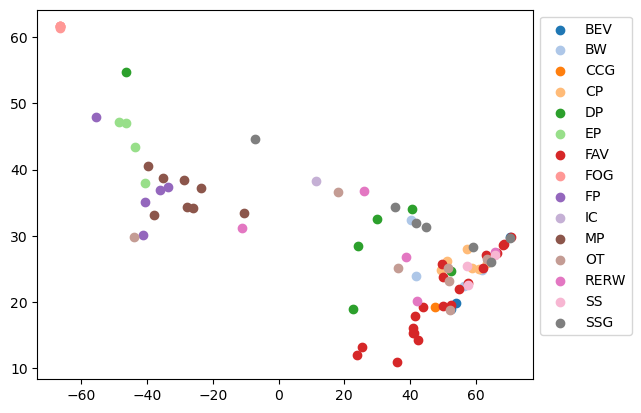

In [ ]:
macros_pca = decomposition.PCA(n_components=2).fit(macros)
fig, ax = plt.subplots()
cmap = mpl.color_sequences['tab20']
color_index = 0
for name, group in food_waste_groups:
    group_macros_reduced = macros_pca.transform(group[['Fat.Perc','Protein.Perc','Carbohydrate.Perc']].copy().to_numpy())
    plt.scatter(group_macros_reduced[:,0], group_macros_reduced[:,1], label=name, color=cmap[color_index])
    color_index+=1
plt.legend(bbox_to_anchor=(1,1))
plt.show()
# macros_reduced = macros_pca.fit_transform(macros)
# plt.scatter(macros_reduced[:,0], macros_reduced[:,1])
# plt.show()

In [138]:
combined_food_waste = pd.read_csv("Food_waste_characterization_combinations.csv")
combined_food_waste_groups = combined_food_waste.groupby('Group')

combined_macros = combined_food_waste[['Fat.Perc','Protein.Perc','Carbohydrate.Perc']].copy().to_numpy()

# combined_food_waste['fats'] = (combined_food_waste['VS.Perc']*combined_food_waste['Fat.Perc'])/100
# combined_food_waste['proteins'] = (combined_food_waste['VS.Perc']*combined_food_waste['Protein.Perc'])/100
# combined_food_waste['carbs'] = (combined_food_waste['VS.Perc']*combined_food_waste['Carbohydrate.Perc'])/100
# combined_macros = combined_food_waste[['fats','proteins','carbs']].copy().to_numpy()

In [142]:
labels = {'0':'Fat %', '1':'Protein %', '2':'Carb %'}
# labels = {'0':'fat per 100g', '1':'protein per 100g', '2':'carbs per 100g'}
fig = px.scatter_3d(combined_macros, x=0, y=1, z=2, labels=labels, color=combined_food_waste['Group'])
fig.show()
# the outlier (from the plane) is potatoes, whose percentages don't add to 100 for some reason

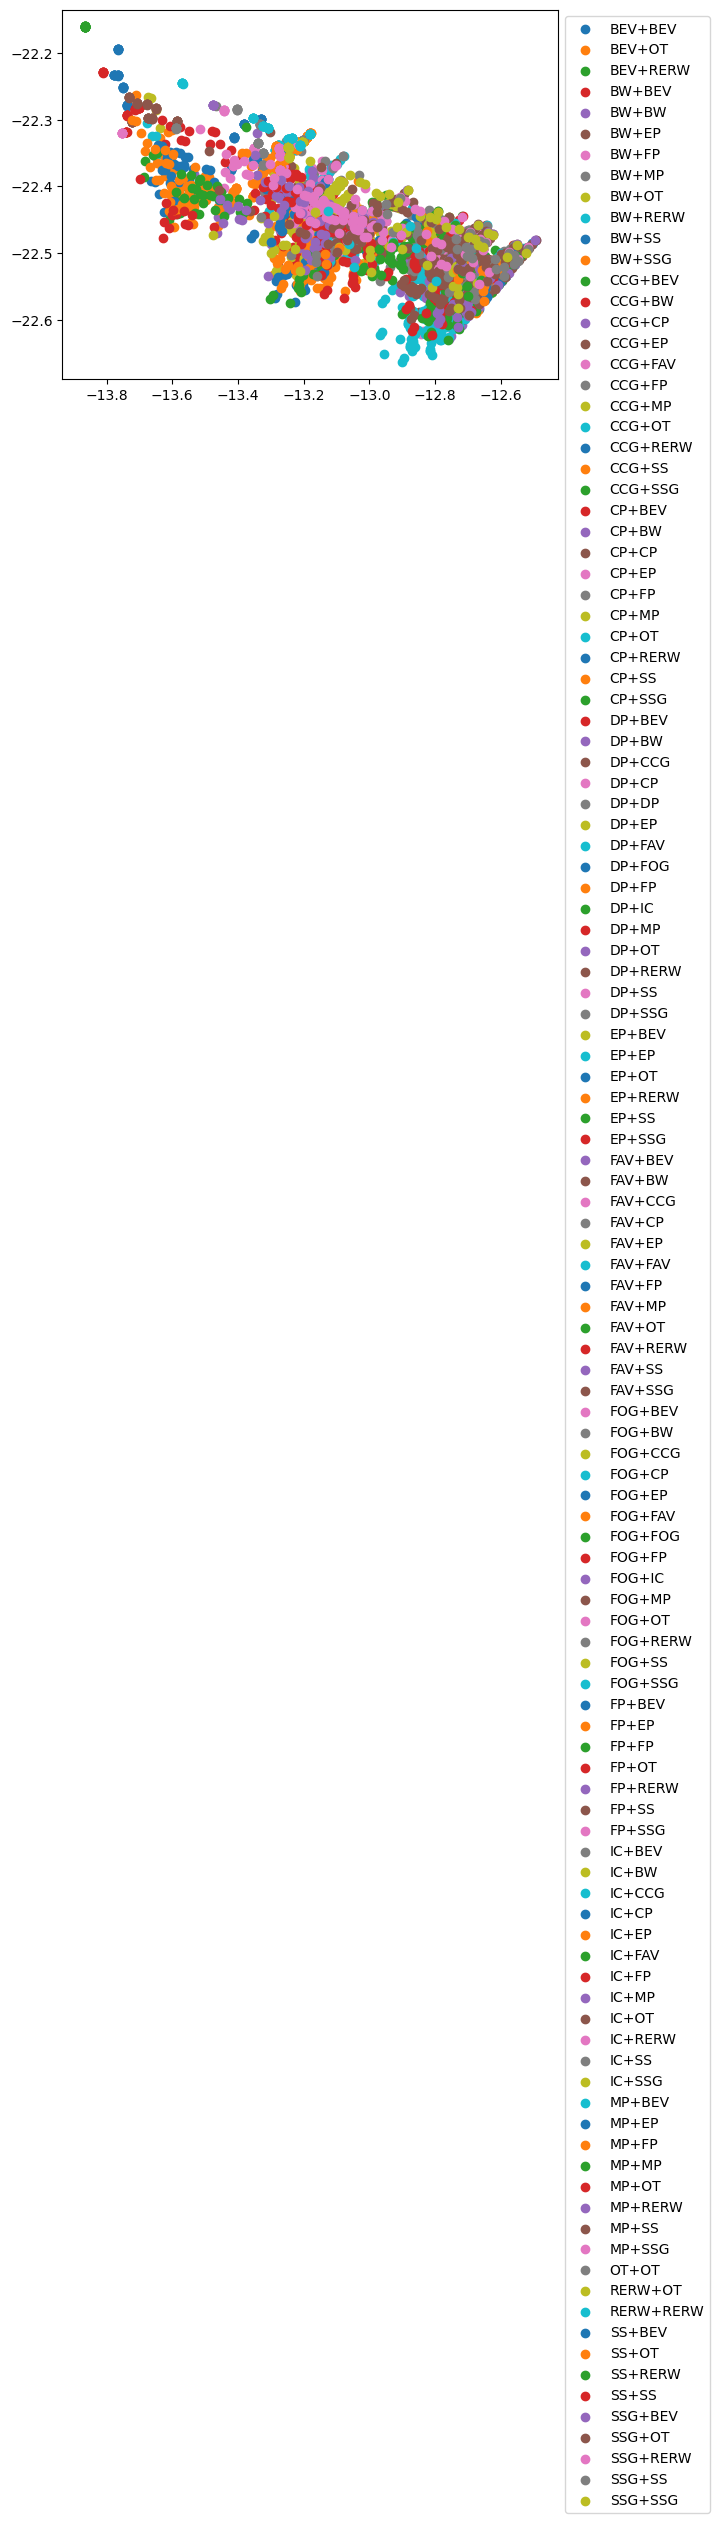

In [144]:
combined_macros_pca = decomposition.PCA(n_components=2).fit(macros)
fig, ax = plt.subplots()
cmap = mpl.color_sequences['tab20']
color_index = 0
for name, group in combined_food_waste_groups:
    combined_group_macros_reduced = combined_macros_pca.transform(group[['Fat.Perc','Protein.Perc','Carbohydrate.Perc']].copy().to_numpy())
    plt.scatter(combined_group_macros_reduced[:,0], combined_group_macros_reduced[:,1], label=name)#, color=cmap[color_index])
    color_index+=1
plt.legend(bbox_to_anchor=(1,1))
plt.show()
# macros_reduced = macros_pca.fit_transform(macros)
# plt.scatter(macros_reduced[:,0], macros_reduced[:,1])
# plt.show()